<!-- DRAFT: Graeme to edit -->
# Day 2 · 07 (full data) — Lab: a foundation model against the selected GFM (20 min)

The original lab 04 runs pretrained foundation models on a CPU subset. Here we put the
strongest of them, **Chronos-2**, next to our selected global model (`GFM_selected`), on the
same 2,000 evaluation series. The research listed this comparison as an open question
(`docs/gfm_learnings.md` §9), so this is new work.

| Variant | What it uses |
|---|---|
| `Chronos2_zs` | zero-shot, sales history only |
| `Chronos2_zs_cov` | zero-shot, with the selected config's future covariates in context |
| `Chronos2_ft` | fine-tuned on every training series, with covariates (GPU, optional) |

The references are `GFM_selected`, LightGBM and SeasonalNaive, read from their saved
forecasts.

Goals

1. Run the Chronos-2 variants on the validation and test windows.
2. Choose a variant on **validation**, then score the test window once.
3. See where Chronos-2 beats the GFM, and where it does not.
4. Probe Chronos-2's price response the way 05b probes the GFM.

**In the chain:** reads the selected config (`gd.selected_config()`), the selected GFM's
probe results (`gp.selected_gfm_probes`) and `00_baselines`, writes `07_foundation`.

<!-- DRAFT: Graeme to edit -->
## Intuition: a well-travelled forecaster against a local expert

Chronos-2 has seen millions of series from many industries, but never this shop. Shown a
series' history, it forecasts the next 14 weeks with no training at all. Our GFM has seen
only this shop, but all of it, with prices and promotions. It is the travelling consultant
against the shop manager: who wins, and on which items?

In [1]:
import functools
import os
import tempfile

import numpy as np
import pandas as pd
import torch
from chronos import Chronos2Pipeline
from chronos.chronos2.preprocess import from_data_frame

import gd_helpers as gd
import gd_plots as gplt
import gd_price as gp

bc = gd.bc
gd.status()
gplt.use_style()

/home/gdavidson/code/time-series-forecasting-bootcamp/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


LOAD (read saved results) | results: results/day2_full | accelerator: gpu


<!-- DRAFT: Graeme to edit -->
## 1. Settings

These set the model size, whether to fine-tune, and the interval levels.

* The full Chronos-2 (≈120M parameters, ≈0.5 GB) on the GPU run; the small one (28M) in a
  CPU smoke run. Weights download once to the Hugging Face cache, outside the repo.
* Fine-tuning is off unless `GD_FM_FINETUNE=1`. It needs a GPU on the full panel.
* Zero-shot forecasts have no random seed: the same input always gives the same forecast.

In [2]:
GPU = torch.cuda.is_available()
DEVICE = "cuda" if GPU else "cpu"
CHRONOS_REPO = gd.CHRONOS_REPO               # the small model in a smoke run
FM_N_SERIES = 20 if gd.SMOKE else None        # None: every eval series
FINETUNE = os.environ.get("GD_FM_FINETUNE") == "1"
FT_STEPS = 5 if gd.SMOKE else 1_000
FT_LR = 1e-6                                  # the library's recommendation for full fine-tuning
FT_BATCH = 32 if gd.SMOKE else 256
BATCH = gd.CHRONOS_BATCH                      # series (target + covariates) per predict batch
LEVELS = [80, 95]
QUANTILES = gd.CHRONOS_QUANTILES              # level -> column suffix
print(f"GPU: {GPU} | model: {CHRONOS_REPO} | fine-tune: {FINETUNE} ({FT_STEPS} steps)")

GPU: True | model: amazon/chronos-2 | fine-tune: False (1000 steps)


<!-- DRAFT: Graeme to edit -->
## 2. Data: the selected config's panel and covariates

`gp.prepare` rebuilds the selected config's training data exactly, so Chronos-2 sees the same
deflated prices, events and calendar terms as the GFM. The context is each series' full
training history. For the validation window the data is rebuilt with
`cutoff=bc.VALID_START`, so the reference price uses only the weeks before it.

In [3]:
cfg = gd.selected_config()
baselines_cfg = gd.load_config("00_baselines")
raw = gd.train_panel()
synthetic_seed = cfg.get("synthetic_seed")
panel, train, test, data = gp.prepare(cfg, panel=raw, synthetic_seed=synthetic_seed)
_, fit_part, valid, _ = gp.prepare(cfg, panel=raw, synthetic_seed=synthetic_seed,
                                   cutoff=bc.VALID_START)
info = gplt.series_table(panel)
covariates = cfg["futr_exog"]

examples = baselines_cfg["examples"]
example_ids = gplt.example_ids(examples)
fm_ids = gd.eval_ids()
if FM_N_SERIES:                      # smoke run: the examples first, then fill up
    rest = [u for u in fm_ids if u not in example_ids]
    fm_ids = (example_ids + rest)[:FM_N_SERIES]
print(f"{len(fm_ids):,} series forecast | covariates: {covariates}")

2,000 series forecast | covariates: ['promo', 'discount_depth', 'price_index']


<!-- DRAFT: Graeme to edit -->
## 3. Chronos-2 in a few lines

Chronos-2 reads a long data frame: one row per series and week, the target, and any
covariates. Covariates that also appear in `future_df` are treated as **known in advance**
(planned price and promotions, events, calendar). We keep its median and the 80% and 95%
bands, named like neuralforecast's columns.

In [4]:
def chronos_forecast(pipe, hist, future, ids, alias, covariates=None) -> pd.DataFrame:
    """Chronos-2 forecasts of the ``H`` weeks after ``hist`` for ``ids``: point and bands."""
    covariates = list(covariates or [])
    df = gd.only(bc.to_nixtla(hist, covariates), ids).sort_values(["unique_id", "ds"])
    future_df = None
    if covariates:
        future_df = gd.only(bc.to_nixtla(future, covariates).drop(columns="y"), ids)
    return gd.chronos_forecast(pipe, df, future_df, alias=alias, quantiles=QUANTILES)


def finetune(pipe, hist, covariates, seed):
    """A copy of Chronos-2 fine-tuned on every series in ``hist`` (covariates known ahead).

    The checkpoint the library writes goes to a temporary folder outside the repo.
    """
    df = bc.to_nixtla(hist, covariates).sort_values(["unique_id", "ds"])
    inputs = from_data_frame(df, target_columns=["y"], prediction_length=bc.H,
                             known_covariates_names=covariates, id_column="unique_id",
                             timestamp_column="ds")
    with tempfile.TemporaryDirectory(ignore_cleanup_errors=True) as tmp:
        return pipe.fit(inputs, prediction_length=bc.H, finetune_mode="full",
                        learning_rate=FT_LR, num_steps=FT_STEPS, batch_size=FT_BATCH,
                        output_dir=tmp, remove_printer_callback=True, seed=seed)

<!-- DRAFT: Graeme to edit -->
Each variant runs once per window: validation (history before `VALID_START`) to compare the
variants, and test to score them. Fine-tuning uses the weeks before `VALID_START` of **all**
eligible series, so one fine-tuned model is honest on both windows. It is the only variant
with a seed, so it runs 3 seeds and the forecast is the seed mean.

In [5]:
@functools.cache
def run_chronos() -> tuple[pd.DataFrame, pd.DataFrame]:
    """All variants on both windows: forecasts (long by ``window``) and the time each step took.

    Cached in memory, so the two tables below come from one run when both are computed.
    """
    seconds = {}
    pipe = Chronos2Pipeline.from_pretrained(CHRONOS_REPO, device_map=DEVICE)
    variants = {"Chronos2_zs": (pipe, None), "Chronos2_zs_cov": (pipe, covariates)}
    if FINETUNE:
        for seed in gd.SEEDS:
            with bc.Timer() as t:
                tuned = finetune(pipe, fit_part, covariates, seed)
            seconds[f"finetune_s{seed}"] = t.seconds
            variants[f"Chronos2_ft_s{seed}"] = (tuned, covariates)
    frames = []
    for window, (hist, future) in {"valid": (fit_part, valid), "test": (train, test)}.items():
        out = None
        for alias, (model, covs) in variants.items():
            with bc.Timer() as t:
                f = chronos_forecast(model, hist, future, fm_ids, alias, covs)
            seconds[f"{alias}_{window}"] = t.seconds
            print(f"{window:5s} {alias:22s} {t.seconds:7.1f}s")
            out = f if out is None else out.merge(f, on=["unique_id", "ds"])
        frames.append(out.assign(window=window))
    timing = pd.DataFrame({"step": list(seconds), "seconds": list(seconds.values())})
    return pd.concat(frames, ignore_index=True), timing


def chronos_forecasts() -> pd.DataFrame:
    """The forecasts from ``run_chronos``."""
    return run_chronos()[0]


def chronos_timing() -> pd.DataFrame:
    """The timings from ``run_chronos``, one row per step."""
    return run_chronos()[1]


fm_all = gd.cached("07_chronos", chronos_forecasts)
timing = gd.cached("07_chronos_seconds", chronos_timing)

<!-- DRAFT: Graeme to edit -->
The fine-tuned forecast is the mean of its seeds, point and bands alike. The table shows how
long each step took.

In [6]:
ft_cols = [c for c in fm_all.columns if c.startswith("Chronos2_ft_s")]
ft_points = [c for c in ft_cols if c in bc.model_columns(fm_all)]
if ft_points:
    fm_all["Chronos2_ft"] = fm_all[ft_points].mean(axis=1)
    for suffix in QUANTILES.values():
        fm_all[f"Chronos2_ft{suffix}"] = fm_all[[f"{c}{suffix}" for c in ft_points]].mean(axis=1)
variants = [c for c in ["Chronos2_zs", "Chronos2_zs_cov", "Chronos2_ft"] if c in fm_all]
fm_valid = fm_all[fm_all["window"] == "valid"].drop(columns="window")
fm_test = fm_all[fm_all["window"] == "test"].drop(columns="window")
timing

,step,seconds
0,Chronos2_zs_valid,1.629255
1,Chronos2_zs_cov_valid,2.861261
2,Chronos2_zs_test,1.434484
3,Chronos2_zs_cov_test,3.130468


<!-- DRAFT: Graeme to edit -->
## 4. Which variant? Decided on the validation window

The variant with the lowest validation median RMSSE goes forward, with the mean and the
cost per 1,000 series alongside. The test window plays no part in the choice.

In [7]:
valid_metrics = gd.score(fm_valid[["unique_id", "ds"] + variants + ft_points], valid, fit_part)
valid_summary = bc.summarise(valid_metrics, fm_valid, valid)
valid_summary = valid_summary.sort_values("median_rmsse").reset_index(drop=True)
n_fm = len(fm_ids)
step_seconds = timing.set_index("step")["seconds"]
valid_seconds = valid_summary["model"].map(lambda m: step_seconds.get(f"{m}_valid", np.nan))
valid_summary["seconds_per_1k_series"] = 1000 * valid_seconds / n_fm
best_variant = valid_summary.loc[valid_summary["model"].isin(variants), "model"].iloc[0]
print(f"best Chronos-2 variant on validation (median RMSSE): {best_variant}")
valid_summary[["model", "median_rmsse", "mean_rmsse", "wape", "seconds_per_1k_series"]].round(3)

best Chronos-2 variant on validation (median RMSSE): Chronos2_zs_cov


,model,median_rmsse,mean_rmsse,wape,seconds_per_1k_series
0,Chronos2_zs_cov,0.574,1.135,0.231,1.431
1,Chronos2_zs,0.701,1.262,0.317,0.815


<!-- DRAFT: Graeme to edit -->
### Reading the result

* Do the covariates help (`zs_cov` against `zs`)? Chronos-2 reads them in context, with no
  training, so a gain here is the price and promotion calendar paying off for free.
* If fine-tuning ran: is its gain bigger than the 02 noise floor? Fine-tuning costs GPU time
  on every refresh.
* Note the cost column: zero-shot takes ≈ 0.8 s per 1,000 series (≈ 1.4 s with covariates).

*Exact numbers vary with seed and hardware.*

<!-- DRAFT: Graeme to edit -->
## 5. On the test window, against the selected GFM

The Chronos-2 rows go on the board. If they cover only a subset of series, their `n_series`
says so, and notebook 10 leaves them out of the standings.

In [8]:
fm_seconds = {m: step_seconds.get(f"{m}_test") for m in variants}
gd.save_forecasts(fm_test[["unique_id", "ds"] + variants], "07_foundation")
gd.record(fm_test[["unique_id", "ds"] + variants], test, train, lab="07 foundation",
          fit_seconds=fm_seconds,
          notes=f"{n_fm} series; {CHRONOS_REPO}; fine-tuned: {bool(ft_points)}")
gd.median_board("07")

,model,median_rmsse,mean_rmsse,wape,n_series,lab,fit_seconds
0,Chronos2_zs_cov,0.512,1.076,0.217,1999,07 foundation,3.130
1,GFM_clean_floor,0.519,2.431,21.871,1999,05c clean + floor (3-seed mean),344.533
2,GFM_clean_floor_clip,0.520,1.078,0.399,1999,"05c clean + floor + clip, capped (3-seed mean)",357.533
3,GFM_floor,0.523,1.488,6.985,1999,05c scaler floor (3-seed mean),362.700
4,GFM_cluster_static,0.526,1.092,0.532,1999,06 clusters (3-seed mean),398.533
5,NHITS_recipe_mean,0.539,1.063,0.251,1999,01 recipe (3-seed mean),249.433
6,NBEATSx_B_cpi_mean,0.540,1.076,0.263,1999,04 price arms (3-seed mean),522.767
7,GFM_per_cluster,0.542,1.098,0.242,1999,06 clusters (3-seed mean),836.467
8,GFM_synthetic,0.546,1.768,0.265,1999,05b synthetic (3-seed mean),361.200
9,GFM_selected,0.546,1.067,0.257,1999,05 selected (3-seed mean),379.767


<!-- DRAFT: Graeme to edit -->
For a like-for-like comparison, every model is scored on the series Chronos-2 forecast.

In [9]:
baselines = pd.read_parquet(gd.FORECAST_DIR / "00_baselines.parquet")
baselines["ds"] = pd.to_datetime(baselines["ds"])
references = ["GFM_selected", "LightGBM", "SeasonalNaive"]
both = fm_test.merge(gd.selected_forecasts(cfg), on=["unique_id", "ds"], how="left")
both = both.merge(baselines[["unique_id", "ds", "LightGBM", "SeasonalNaive"]],
                  on=["unique_id", "ds"], how="left")
test_metrics = gd.score(both, test, train)
rmsse = gd.per_series(test_metrics)
test_summary = bc.summarise(test_metrics, both, test).sort_values("median_rmsse")
test_summary[["model", "median_rmsse", "mean_rmsse", "wape", "n_series"]].round(3)

,model,median_rmsse,mean_rmsse,wape,n_series
0,Chronos2_zs_cov,0.512,1.076,0.217,1999
1,GFM_selected,0.520,1.078,0.399,1999
2,LightGBM,0.572,1.161,0.297,1999
3,Chronos2_zs,0.645,1.202,0.306,1999
4,SeasonalNaive,0.929,1.525,0.438,1999


<!-- DRAFT: Graeme to edit -->
### Reading the result

* Median RMSSE first: where does the chosen variant sit against `GFM_selected` (≈ 0.512
  against ≈ 0.520)? The mean sits alongside. The GFM is 05c's model (cleaned prices, scaler
  floor, input clip, capped); 05's was 0.546. Its WAPE (≈ 0.40) is high because one best
  seller (`6653_S1`) blows up in one seed, and the cap at 3× its largest week still leaves
  millions of units: the median and mean are not affected.
* The research found LightGBM the most accurate model but untrustworthy on price (§5,
  [100k set]). If Chronos-2 is close on accuracy, the same question applies to it.

*Exact numbers vary with seed and hardware.*

## 6. Where the errors are

Per-series RMSSE for every model (F2): a histogram, a cumulative curve and a box plot by
class.

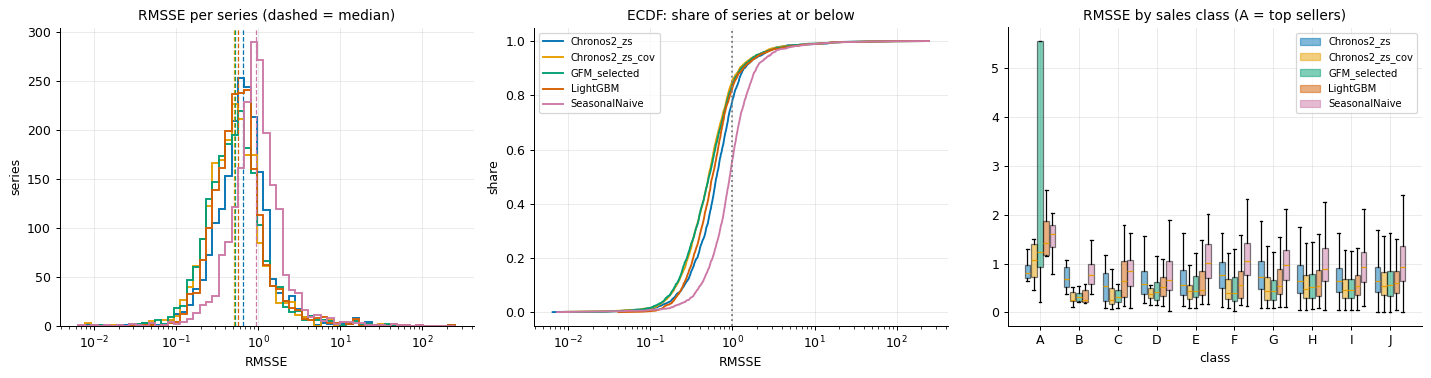

In [10]:
gplt.plot_error_dist(rmsse, info, models=variants + references)

<!-- DRAFT: Graeme to edit -->
By demand type (as in the original lab): smooth, erratic, intermittent and lumpy series.

In [11]:
by_type = rmsse.join(info["demand_type"]).groupby("demand_type")
by_type.median().round(3).assign(n=by_type.size())

,Chronos2_zs,Chronos2_zs_cov,GFM_selected,LightGBM,SeasonalNaive,n
demand_type,,,,,,
erratic,0.693,0.375,0.391,0.541,0.898,287
intermittent,0.667,0.586,0.589,0.594,1.015,340
lumpy,0.717,0.583,0.524,0.554,0.918,188
smooth,0.623,0.527,0.537,0.580,0.920,1185


<!-- DRAFT: Graeme to edit -->
### Marginal wins: the best Chronos-2 variant against the selected GFM

Bars above 0.5 are classes where Chronos-2 wins more series than it loses.

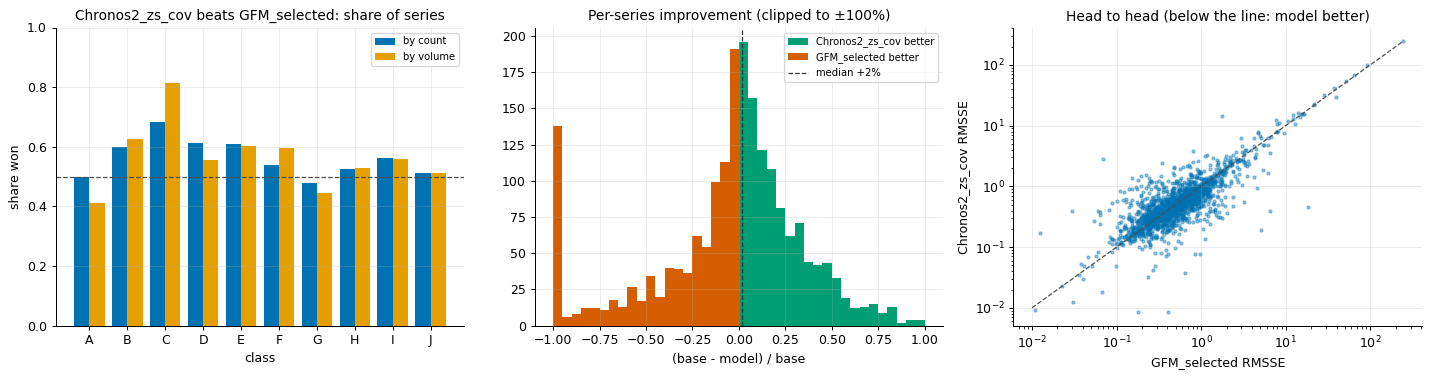

,win_share,win_share_volume,n
sale_class,,,
A,0.500,0.410,4.0
B,0.600,0.627,10.0
C,0.684,0.813,19.0
D,0.613,0.555,31.0
E,0.609,0.604,46.0
F,0.537,0.597,67.0
G,0.479,0.446,96.0
H,0.527,0.529,148.0
I,0.564,0.557,259.0


In [12]:
gplt.plot_wins(rmsse, info, model=best_variant, baseline="GFM_selected")

<!-- DRAFT: Graeme to edit -->
## 7. The example series

Chronos-2's 80% band is shaded around its forecast. Watch the promo weeks: does it follow the
planned price, or smooth over it?

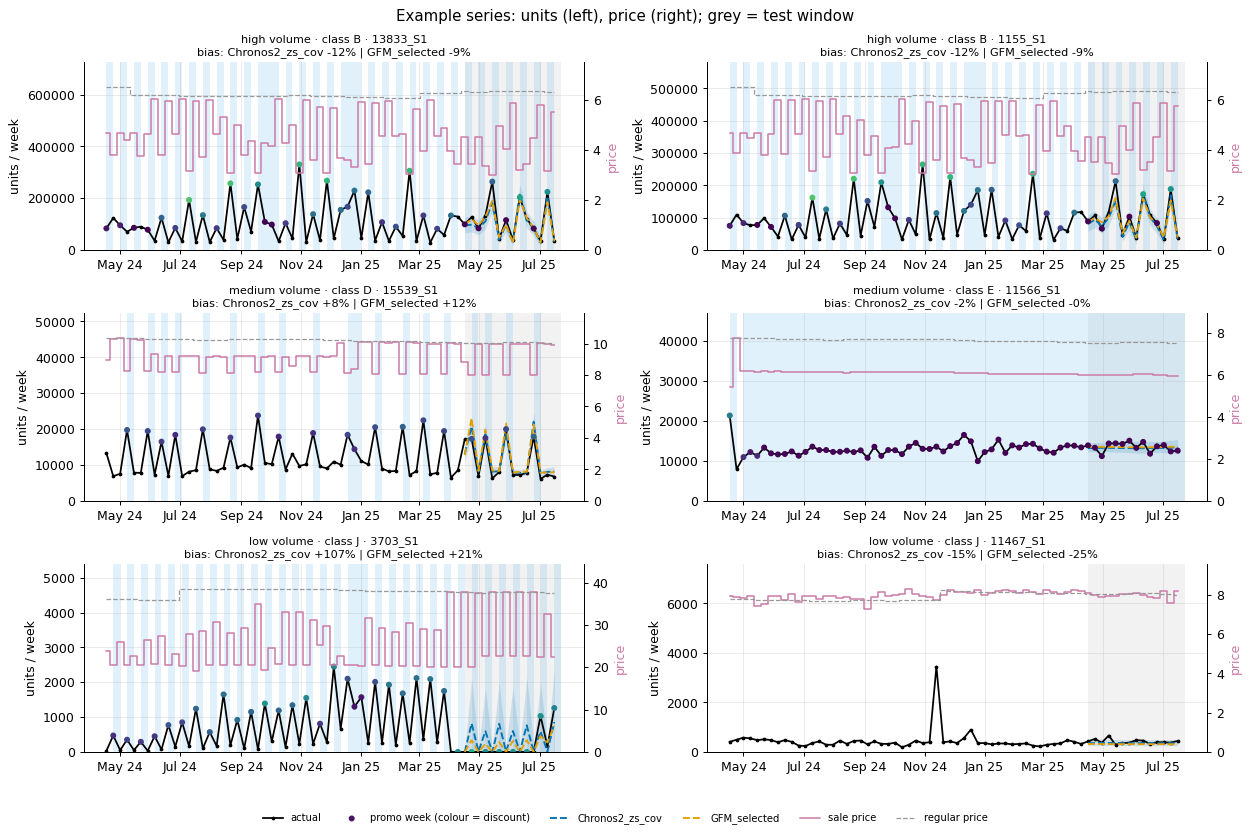

In [13]:
shown = [best_variant, "GFM_selected"]
bands = {best_variant: (f"{best_variant}-lo-80", f"{best_variant}-hi-80")}
gplt.plot_series_price(panel, examples, both, models=shown, bands=bands)

<!-- DRAFT: Graeme to edit -->
## 8. Price response: does Chronos-2 read the planned price?

Chronos-2 reads the covariates in context: it sees how each series' sales moved with its
own past prices and promotions, and carries that into the forecast. It has no price weights
of its own to inspect, so we ask it "what if?", as 05b asked the GFM. Same report series,
same probes, same random promotion calendars (`gp.price_probes`, `gp.promo_calendars`):

* **fixed probes:** −10%, −20%, −30% and +20% in every test week (sustained) or in week 5
  only (pulse), moving the price alone (`_price`) or rebuilding every input built from it
  (`_all`, the headline: a one-week 20% cut), and once with the promotion flag on;
* **random promotion calendars:** three one-week cuts per series at random depths of 10–30%,
  in weeks with no event and no planned promotion, five draws.

Each probe is one more forecast of the report series: seconds on a GPU.

In [14]:
PROBED = "Chronos2_zs_cov"           # the variant that sees the price
probe_ids = gp.report_ids(train, [u for u in fm_ids if u in set(gd.eval_ids())])
probe_hist = gd.only(bc.to_nixtla(train, covariates), probe_ids)
probe_futr = gd.only(bc.to_nixtla(test, covariates).drop(columns="y"), probe_ids)
probe_calendars = gp.promo_calendars(probe_futr, probe_ids)
print(f"{len(probe_ids):,} report series | {len(probe_calendars):,} calendar cuts | price "
      f"inputs rebuilt, largest gap from the data: {gp.rebuild_check(probe_hist, probe_futr)}")


def chronos_predict(pipe):
    """``predict(futr)`` for Chronos-2 with the covariates, on the report series."""
    def predict(futr: pd.DataFrame) -> pd.DataFrame:
        ids = sorted(futr["unique_id"].unique())
        df = gd.only(probe_hist, ids).sort_values(["unique_id", "ds"])
        future_df = futr[["unique_id", "ds"] + covariates].sort_values(["unique_id", "ds"])
        out = pipe.predict_df(df, future_df=future_df, id_column="unique_id",
                              timestamp_column="ds", target="y", prediction_length=bc.H,
                              quantile_levels=list(QUANTILES), batch_size=BATCH, freq=bc.FREQ)
        return out[["unique_id", "ds", "predictions"]].rename(columns={"predictions": "yhat"})
    return predict


@functools.cache
def run_chronos_probes() -> dict:
    """Fixed probes and calendar probes for zero-shot Chronos-2 with covariates."""
    predict = chronos_predict(Chronos2Pipeline.from_pretrained(CHRONOS_REPO, device_map=DEVICE))
    with bc.Timer() as t:
        out = {"probe7b": gp.price_probes(predict, probe_hist, probe_futr, probe_ids),
               "calendar": gp.calendar_probe(predict, probe_hist, probe_futr, probe_calendars)}
    print(f"Chronos-2 probes: {t.seconds:.0f}s")
    return out


chronos_probe = gd.cached("07_chronos_probe", lambda: run_chronos_probes()["probe7b"])
chronos_calendar = gd.cached("07_chronos_calendar", lambda: run_chronos_probes()["calendar"])
probe_table = gp.probe_report(chronos_probe)
calendar_table = gp.calendar_report(chronos_calendar)
probe_table.round(3)

680 report series | 8,152 calendar cuts | price inputs rebuilt, largest gap from the data: 4.440892098500626e-16


,mode,shock,n,median_elasticity,median_lift,share_right_sign,share_at_bar,median_spill
0,pulse_all,-0.3,680,-1.222,0.536,0.912,0.797,-0.005
1,pulse_all,-0.2,680,-1.433,0.371,0.912,0.809,-0.004
2,pulse_all,-0.1,680,-1.538,0.174,0.909,0.797,-0.002
3,pulse_all,0.2,680,-1.352,-0.227,0.900,0.771,0.006
4,pulse_all_promo,-0.3,680,-1.409,0.635,0.907,0.801,-0.006
5,pulse_all_promo,-0.2,680,-1.646,0.434,0.906,0.818,-0.004
6,pulse_all_promo,-0.1,680,-1.838,0.205,0.879,0.800,-0.002
7,pulse_price,-0.3,680,-0.856,0.347,0.884,0.744,0.000
8,pulse_price,-0.2,680,-0.972,0.239,0.882,0.759,-0.000
9,pulse_price,-0.1,680,-1.057,0.116,0.882,0.760,-0.000


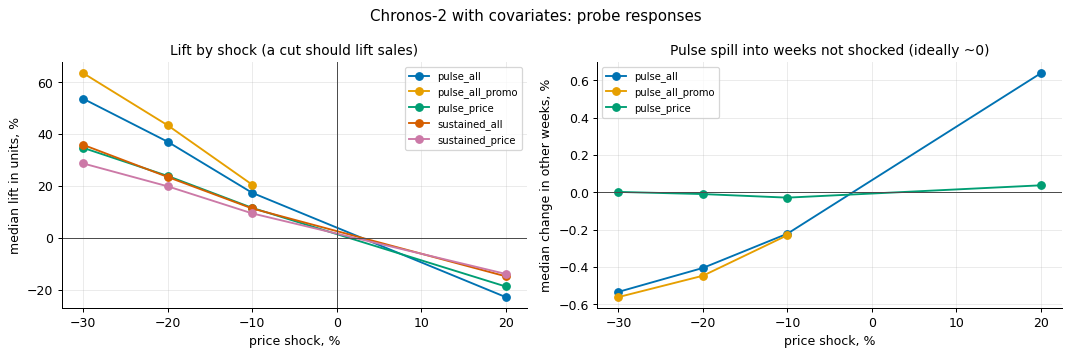

In [15]:
gplt.plot_probe(probe_table, title="Chronos-2 with covariates: probe responses")

<!-- DRAFT: Graeme to edit -->
Now the lift by cut depth under the random calendars (F13), against the GFM in use (its
3-seed probes, from 05c's test fits) and the lift the data's own elasticity implies.

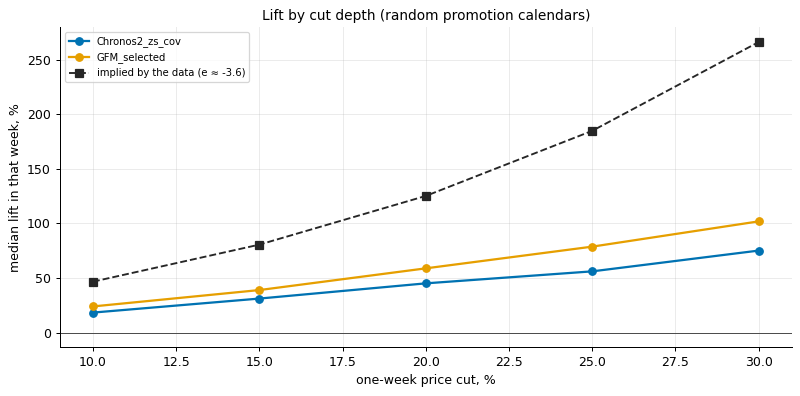

,n,median_elasticity,median_lift,share_right_sign,share_at_bar,median_spill
Chronos2_zs_cov,680.0,-1.433,0.371,0.912,0.809,-0.004
GFM_selected,680.0,-1.823,0.503,0.997,0.982,0.005


In [16]:
gfm_probes, gfm_calendar = gp.selected_gfm_probes(cfg)
gfm_calendar = gfm_calendar.set_index("depth")
empirical_all = gp.empirical_elasticity(train, probe_ids).iloc[0]["elasticity"]
depths = list(gp.CAL_DEPTHS)
lift_by_depth = pd.DataFrame({
    PROBED: calendar_table.set_index("depth")["median_lift"],
    "GFM_selected": gfm_calendar["median_lift"],
    "implied by the data": pd.Series(gp.implied_lift(empirical_all, depths), index=depths)})
lift_by_depth.index.name = "depth"
gplt.plot_lift_by_depth({PROBED: lift_by_depth[PROBED],
                         "GFM_selected": lift_by_depth["GFM_selected"]},
                        references={f"implied by the data (e ≈ {empirical_all:.1f})":
                                    lift_by_depth["implied by the data"]})
headlines = pd.DataFrame({PROBED: gp.headline(probe_table),
                          "GFM_selected": gp.headline(gfm_probes)}).T
headlines.round(3)

<!-- DRAFT: Graeme to edit -->
### Reading the result

* Headline first: the median elasticity and lift for a one-week 20% cut, for Chronos-2 and
  the GFM. Right sign means a cut lifts sales; the research's bar was −0.3 or stronger.
* Then the depth chart: does lift grow with the depth of the cut, as it should? A flat line
  means the model reads that there is a promotion, not how deep it is.
* Chronos-2 learns each series' response from that series alone. Series with few past price
  moves give it little to go on; the GFM pools all 17,000.
* Here Chronos-2 does read the price. A one-week 20% cut gives a median elasticity of
  ≈ −1.43 (lift ≈ +37%, ≈ +43% with the promotion flag on), against the GFM's ≈ −1.82
  (≈ +50%). Lift grows with depth: ≈ +18% at 10%, ≈ +45% at 20%, ≈ +75% at 30%.
* It is less consistent than the GFM: ≈ 90% of calendar cuts lift its forecast, against
  ≈ 99% for the GFM, and ≈ 81% of series reach the −0.3 bar (the GFM: ≈ 98%). Both stay
  well below the lift the data implies (≈ +125% at 20%). Spill is about zero: the cut stays
  in its own week.

*Exact numbers vary with seed and hardware.*

In [17]:
test_median = test_summary.set_index("model")["median_rmsse"]
gd.save_config("07_foundation", {
    "repo": CHRONOS_REPO,
    "n_series": n_fm,
    "covariates": covariates,
    "variants": variants,
    "finetune": {"ran": bool(ft_points), "steps": FT_STEPS, "learning_rate": FT_LR,
                 "mode": "full", "seed_columns": ft_points},
    "selected_variant": best_variant,
    "selection_rule": "lowest median RMSSE on the validation window",
    "median_rmsse_valid": valid_summary.set_index("model")["median_rmsse"].round(4).to_dict(),
    "median_rmsse_test": test_median.round(4).to_dict(),
    "seconds": step_seconds.round(1).to_dict(),
    "gpu": GPU,
    "probed_variant": PROBED,
    "probes": probe_table.round(4).to_dict("records"),
    "calendar": calendar_table.round(4).to_dict("records"),
    "headline": gp.headline(probe_table),
})

PosixPath('/home/gdavidson/code/time-series-forecasting-bootcamp/results/day2_full/configs/07_foundation.json')

<!-- DRAFT: Graeme to edit -->
## Discussion

* Chronos-2 sees at most ≈ 100 weekly points per series here. What does it bring that a
  model trained on 17,000 of this shop's series does not?
* In the wins by class, is Chronos-2 strongest where history is sparse, and weakest where
  promotions drive the spikes? What would that tell you about using both?
* Chronos-2's price response comes from each series' own history, read in context. Would you
  trust it for an item that has never been discounted?

**Try it:** set `cross_learning=True` in `chronos_forecast` so Chronos-2 shares information
across the series in a batch, and compare the validation table.